In [1]:
import warnings
warnings.filterwarnings(action='ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import koreanize_matplotlib

# 주식 정보 읽어오기

FinanceDataReader는 한국과 미국을 비롯한 글로벌 금융 시장의 주식, 지수, 암호화폐 등 다양한 금융 데이터와 종목 리스트를 손쉽게 수집하고 분석할 수 있도록 도와주는 파이썬 라이브러리로 복잡한 웹 크롤링이나 API 인증 과정 없이 몇 줄의 코드로 다양한 거래소의 데이터를 판다스 데이터프레임 형태로 가져올 수 있어, 주가 분석이나 퀀트 투자 등에 널리 쓰인다.

주식 정보(거래소, 종목)를 읽어오기 위해서 FinanceDataReader를 설치하고 import 한다.  
`!pip install finance-DataReader`

In [3]:
import FinanceDataReader as fdr

FinanceDataReader에서 제공하는 종목 리스트는 거래소 및 시장별로 세분화되어 있고 거래소 정보를 얻어오는 `StockListing('시장키워드')`를 사용한다.

## 한국 시장 전 종목 및 특수 리스트  
fdr.StockListing(`'KRX'`) # `KRX 전체`(코스피 + 코스닥 + 코넥스)  
fdr.StockListing(`'KOSPI'`) # `코스피`  
fdr.StockListing(`'KOSDAQ'`) # `코스닥`  
fdr.StockListing(`'KONEX'`) # `코넥스`  
fdr.StockListing(`'KRX-DELISTING'`) # `상장폐지 종목`  
fdr.StockListing(`'KRX-ADMINISTRATIVE'`) # `관리종목`  
fdr.StockListing(`'KRX-MARCAP'`) # `시가총액 순 정렬`

## 미국 시장 및 주요 지수 구성 종목
fdr.StockListing(`'S&P500'`) # `S&P 500`  
fdr.StockListing(`'NASDAQ'`) # `나스닥 거래소`  
fdr.StockListing(`'NYSE'`) # `뉴욕 증권 거래소`  
fdr.StockListing(`'AMEX'`) # `아멕스 거래소`

## 글로벌 해외 주요 거래소
fdr.StockListing(`'SSE'`) # `상해(중국)`  
fdr.StockListing(`'SZSE'`) # `심천(중국)`  
fdr.StockListing(`'HKEX'`) # `홍콩`  
fdr.StockListing(`'TSE'`) # `도쿄(일본)`  
fdr.StockListing(`'HOSE'`) # `호치민(베트남)`

## ETF 리스트
fdr.StockListing(`'ETF/KR'`) # `국내 상장 ETF 전체`

## 대한민국 주식 정보 가져오기

In [7]:
fdr.StockListing('KRX')

,Code,ISU_CD,Name,Market,Dept,Close,ChangeCode,Changes,ChagesRatio,Open,High,Low,Volume,Amount,Marcap,Stocks,MarketId,lateInfoMsgCd
0,005930,KR7005930003,삼성전자,KOSPI,NaN,204500,1,5600,2.82,197100,206000,196300,10089772,2025576086600,1195563975336000,5846278608,STK,ME005
1,000660,KR7000660001,SK하이닉스,KOSPI,NaN,1284000,1,72000,5.94,1206000,1287000,1193000,2105961,2607613666000,937952196660000,730492365,STK,ME005
2,005935,KR7005931001,삼성전자우,KOSPI,NaN,163700,1,4700,2.96,160400,164600,156000,2492280,400754080200,131348165931100,802371203,STK,ME005
3,402340,KR7402340004,SK스퀘어,KOSPI,NaN,790000,1,30000,3.95,755000,792000,737000,435885,331416376500,104219958420000,131923998,STK,ME005
4,373220,KR7373220003,LG에너지솔루션,KOSPI,NaN,330500,3,0,0.00,328500,336500,327000,125013,41578598500,77337000000000,234000000,STK,ME005
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2871,001527,KR7001522002,동양2우B,KOSPI,NaN,6770,2,-2010,-22.89,10200,11410,6320,85842,663854410,1392622850,205705,STK,ME005
2872,266170,KR7266170000,레드우즈,KONEX,일반기업부,1050,3,0,0.00,0,0,0,0,0,1366092000,1301040,KNX,ME005
2873,390110,KR7390110005,애니메디솔루션,KONEX,일반기업부,132,2,-13,-8.97,164,164,124,2135,273989,1280010204,9697047,KNX,ME005
2874,296520,KR7296520000,가이아코퍼레이션,KONEX,일반기업부,274,1,35,14.64,274,274,274,1,274,1278760192,4667008,KNX,ME005


특정 종목에 대한 정보를 얻어오려면 `fdr.DataReader('종목코드'[, '시작일'[, '종료일']])`를 사용한다.

`Date`: 날짜    
`Open`: 해당 거래일의 장 시작시 체결된 첫 가격  
`High`: 해당 거래일 동안 주가가 기록한 가장 높은 가격  
`Low`: 해당 거래일 동안 주가가 기록한 가장 낮은 가격  
`Close`: 해당 거래일의 장 마감시 체결된 마지막 가격, 주가 분석 시 가장 흔하게 기준값으로 사용된다.  
`Volume`: 해당 거래일 동안 매매가 체결된 주식의 총 수량  
`Change`: 전일 종가 대비 당일 종가의 등락 변동 백분율

삼성전자(005930)의 상장일 부터 현재까지 주가 정보를 얻어온다.

In [11]:
fdr.DataReader('005930')

,Open,High,Low,Close,Volume,Change
Date,,,,,,
2014-08-19,25280,25460,25060,25080,200888,NaN
2014-08-20,25280,25420,25020,25220,188612,0.005582
2014-08-21,25100,25220,24620,24700,342108,-0.020619
2014-08-22,24900,24940,24700,24940,168153,0.009717
2014-08-25,24620,24620,24420,24560,231544,-0.015237
...,...,...,...,...,...,...
2026-11-05,213000,213500,199800,201500,24657743,-0.090293
2026-11-06,180000,196500,179200,193500,35516270,-0.039702
2026-11-09,187200,195400,183800,187000,19855892,-0.033592


삼성전자(005930)의 2023-01-01 부터 현재까지 주가 정보를 얻어온다.

In [9]:
fdr.DataReader('005930', '2023-01-01')

,Open,High,Low,Close,Volume,Change
Date,,,,,,
2023-01-02,55500,56100,55200,55500,10031448,0.003617
2023-01-03,55400,56000,54500,55400,13547030,-0.001802
2023-01-04,55700,58000,55600,57800,20188071,0.043321
2023-01-05,58200,58800,57600,58200,15682826,0.006920
2023-01-06,58300,59400,57900,59000,17334989,0.013746
...,...,...,...,...,...,...
2026-11-05,213000,213500,199800,201500,24657743,-0.090293
2026-11-06,180000,196500,179200,193500,35516270,-0.039702
2026-11-09,187200,195400,183800,187000,19855892,-0.033592


삼성전자(005930)의 2025년 주가 정보를 얻어온다.

In [13]:
samsung_df = fdr.DataReader('005930', '2025-01-01', '2025-12-31')
samsung_df

,Open,High,Low,Close,Volume,Change
Date,,,,,,
2025-01-02,52700,53600,52300,53400,16630538,0.003759
2025-01-03,52800,55100,52800,54400,19318046,0.018727
2025-01-06,54400,56200,54300,55900,19034284,0.027574
2025-01-07,56800,57300,55400,55400,17030235,-0.008945
2025-01-08,54800,57500,54700,57300,26593553,0.034296
...,...,...,...,...,...,...
2025-12-23,110900,112500,110400,111500,20419187,0.009050
2025-12-24,112400,112400,110900,111100,12492939,-0.003587
2025-12-26,112400,117000,112400,117000,34018174,0.053105


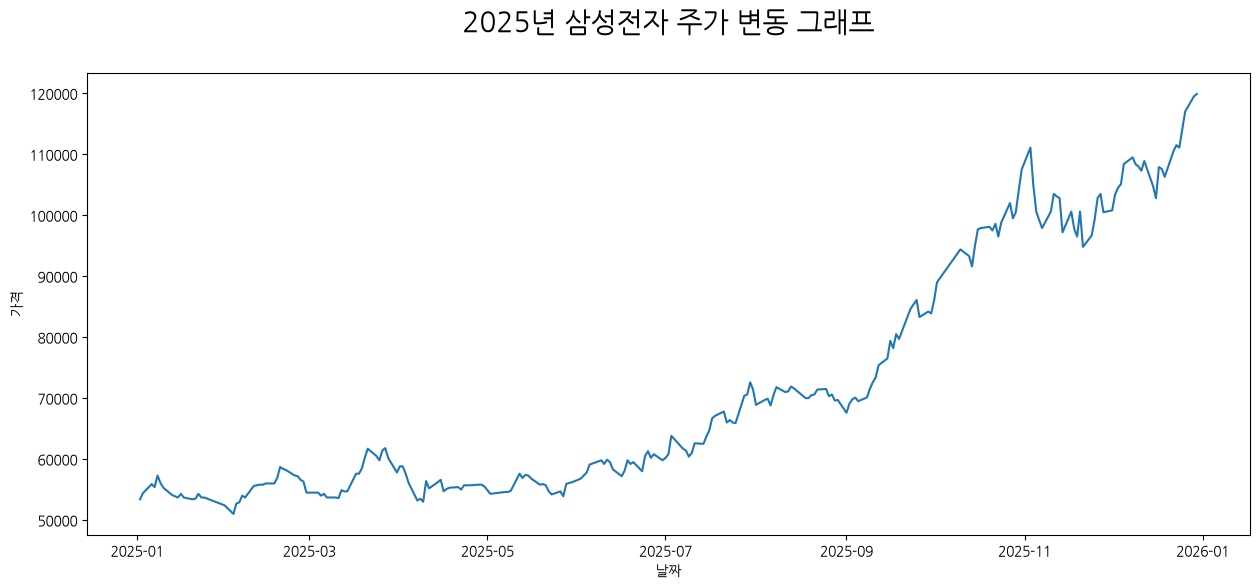

In [20]:
plt.figure(figsize=[15, 6])
sns.lineplot(data=samsung_df, x=samsung_df.index, y=samsung_df.Close)
plt.title('2025년 삼성전자 주가 변동 그래프', pad=30, fontsize=20)
plt.xlabel('날짜')
plt.ylabel('가격')
plt.show()

## 미국 주식 정보 가져오기

In [22]:
fdr.StockListing('NASDAQ').head(10)

100%|██████████| 3983/3983 [00:04<00:00, 853.96it/s]


,Symbol,Name,IndustryCode,Industry
0,AAPL,Apple Inc.,57106020,전화 및 소형 장치
1,NVDA,NVIDIA Corporation,57101010,반도체
2,MSFT,Microsoft Corporation,57201020,소프트웨어
3,AMZN,Amazon.com Inc,53402010,백화점
4,SPCX,Space Exploration Technologies Corp,57401020,무선 통신 서비스
5,GOOGL,Alphabet Inc. Class A,57201030,온라인 서비스
6,META,Meta Platforms Inc.,57201030,온라인 서비스
7,GOOG,Alphabet Inc. Class C,57201030,온라인 서비스
8,AVGO,Broadcom Inc,57101010,반도체
9,TSLA,Tesla Inc,53101010,자동차 및 트럭 제조


애플(AAPL)의 2025년 주가 정보를 얻어온다.

In [35]:
apple_df = fdr.DataReader('AAPL', '2025-01-01', '2025-12-31')
apple_df

,Open,High,Low,Close,Volume,Adj Close
2024-12-31,252.440002,253.279999,249.429993,250.419998,39480700,248.615799
2025-01-02,248.929993,249.100006,241.820007,243.850006,55740700,242.093140
2025-01-03,243.360001,244.179993,241.889999,243.360001,40244100,241.606689
2025-01-06,244.309998,247.330002,243.199997,245.000000,45045600,243.234848
2025-01-07,242.979996,245.550003,241.350006,242.210007,40856000,240.464951
...,...,...,...,...,...,...
2025-12-23,270.839996,272.500000,269.559998,272.359985,29642000,271.620667
2025-12-24,272.339996,275.429993,272.200012,273.809998,17910600,273.066711
2025-12-26,274.160004,275.369995,272.859985,273.399994,21521800,272.657837
2025-12-29,272.690002,274.359985,272.350006,273.760010,23715200,273.016876


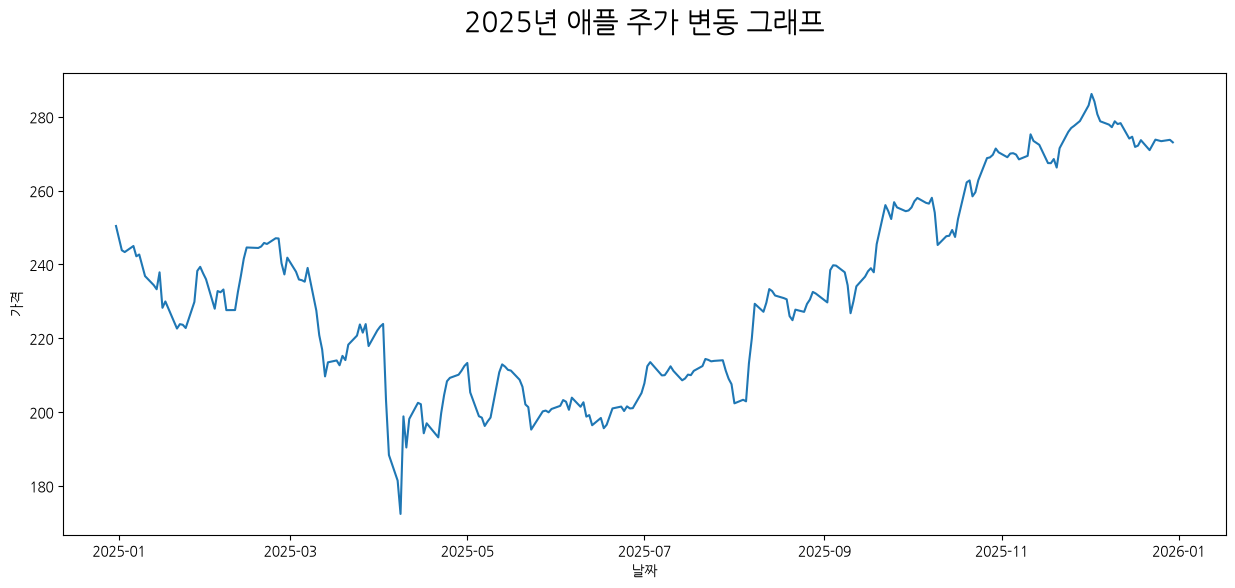

In [36]:
plt.figure(figsize=[15, 6])
sns.lineplot(data=apple_df, x=apple_df.index, y=apple_df.Close)
plt.title('2025년 애플 주가 변동 그래프', pad=30, fontsize=20)
plt.xlabel('날짜')
plt.ylabel('가격')
plt.show()

# 시계열 데이터

## 시계열 데이터 패턴

`추세(trand)`: 시계열 데이터가 시간에 따라서 증가하거나 감소하는 경향을 보이는 패턴  
`계절성(seasonality)`: 시계열 데이터가 일정한 주기를 가지고 반복되는 패턴  
`순환성(cyclical)`: 추세와는 달리, 일정한 주기를 가지고 반복되지만 주기의 길이가 일정하지 않은 패턴  
`불규칙성(irregular)`: 지진, 홍수, 파업, 코로나와 같은 특수한 요인에 의해 발생하는 불규칙한 패턴

## 시계열 데이터 분석

`분해법`: 시계열 데이터가 가지는 추세, 계절성, 주기, 불규칙성과 같은 구성요소를 분해해서 분석  
`시간 영역 분석법`  
① 자기 회귀(Auto Regressive, AR) 모형  
&nbsp;&nbsp;&nbsp;현재의 시계열 값이 과거의 자기 자신의 값들에 영향을 받는다고 가정하는 모형이다. 즉, '어제의 나, 그제의 나'가 오늘의 나를 만든다는 개념이다.  
② 이동 평균(Moving Average, MA) 모형  
&nbsp;&nbsp;&nbsp;현재의 시계열 값이 과거의 오차(white noise, 백색 잡음)들의 선형 결합으로 이루어져 있다고 보는 모형이다.  
③ 자기 회귀 이동 평균(Auto Regressive Moving Average, ARMA) 모형  
&nbsp;&nbsp;&nbsp;시계열 데이터가 있을 때 AR 특성과 MA 특성을 동시에 가지고 있을 때 사용하는 모형이다.  
④ 자기 회귀 누적 이동 평균(Auto Regressive Integrated Moving Average, ARIMA) 모형  
&nbsp;&nbsp;&nbsp;ARMA 모형의 한계를 극복하기 위해, 차분 단계를 추가한 모형이다.

# 시계열 데이터 전처리

## 시계열 데이터 만들기

In [45]:
df = pd.DataFrame(
    {'date': ['2022-01-03', '2024-11-22', '2025-01-15'], 'name': ['홍길동', '임꺽정', '장길산']}
)
df

,date,name
0,2022-01-03,홍길동
1,2024-11-22,임꺽정
2,2025-01-15,장길산


In [46]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   date    3 non-null      str  
 1   name    3 non-null      str  
dtypes: str(2)
memory usage: 180.0 bytes


to_datetime() 메소드로 str 타입을 datetime 타입으로 변환한다.

In [47]:
df['date'] = pd.to_datetime(df.date)

In [48]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    3 non-null      datetime64[us]
 1   name    3 non-null      str           
dtypes: datetime64[us](1), str(1)
memory usage: 180.0 bytes


set_index() 메소드로 특정 시리즈(컬럼)을 인덱스로 설정할 수 있다.

In [49]:
df = df.set_index(['date'])
df

,name
date,
2022-01-03,홍길동
2024-11-22,임꺽정
2025-01-15,장길산


In [50]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 3 entries, 2022-01-03 to 2025-01-15
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   name    3 non-null      str  
dtypes: str(1)
memory usage: 48.0 bytes


## 결측치 처리

결측치 확인

isnull() 메소드 또는 isna() 메소드 실행 결과에 sum() 메소드를 실행하면 결측치의 개수를 확인할 수 있다.

In [59]:
df = pd.DataFrame(
    {'date': ['2022-01-03', '2024-11-22', '2024-12-01', '2025-01-15'], 'name': [0.1, 2.0, np.nan, 1.2]}
)
df['date'] = pd.to_datetime(df.date)
df = df.set_index(['date'])
df

,name
date,
2022-01-03,0.1
2024-11-22,2.0
2024-12-01,NaN
2025-01-15,1.2


In [60]:
df.isnull().sum()

name    1
dtype: int64

결측치 제거

dropna() 메소드로 결측치를 제거할 수 있다.

`axis`: 0이 기본값이고 결측치가 포함된 행을 제거하고, 1을 결측치가 포함된 열을 제거한다.

In [61]:
df.dropna()

,name
date,
2022-01-03,0.1
2024-11-22,2.0
2025-01-15,1.2


결측치를 데이터로 채우기

`fillna()` 메소드로 특정 값으로 결측치를 채운다.  
`ffill()` 메소드로 이전 값으로 결측치를 채운다.  
`bfill()` 메소드로 다음 값으로 결측치를 채운다.  
`interpolate()` 메소드로 이전 값과 다음 값의 평균으로 결측치를 채운다.